# SAM calibration gap across training length (evaluation demo)

**Question.** Does sharpness-aware minimization (SAM) improve test accuracy and calibration over plain SGD for a small convolutional network on Fashion-MNIST, and does the SAM-minus-SGD calibration gap change with training length?

**What this notebook does.** It is an *evaluation only* notebook. No model is trained and no logits are recomputed. It reads the saved outputs of two earlier SAM-vs-SGD runs (source 1: 5 seeds, 40 epochs; source 2: 3 seeds, 60 epochs with per-epoch validation values), computes the paired gap (SAM minus SGD) in test and validation expected calibration error (ECE, 15 bins), NLL, and accuracy, adds temperature-scaled SGD controls, writes a gap table and a six-panel figure, and checks the outputs against the evaluation JSON schema.

**Data.** `mini_demo_data.json` (about 0.35 MB) holds the datasets the script reads from the two sources, plus the schema. It is loaded from GitHub with a local fallback.

**What you will see.** A gap table printed from the run, and a six-panel figure. The two trajectories are reported separately and are never pooled.

## Install dependencies

Loguru is installed everywhere; the core scientific packages are pinned to Colab's versions only when running outside Colab.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru is not pre-installed on Colab, always install
_pip('loguru==0.8.0')

# numpy, scipy, matplotlib, jsonschema are pre-installed on Colab, install locally only
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0', 'jsonschema==4.26.0')

## Imports

The original import block, followed by the shared figure style.

In [2]:
import ast
import csv
import itertools
import json
import math
import os
import subprocess
import sys
from pathlib import Path

import jsonschema
import numpy as np
from loguru import logger
from scipy import stats

import matplotlib.pyplot as plt

# One colour per role, the same in every notebook of this run and in the paper's figures.
COLOURS = {
    "method": "#0173B2",  # the paper's own method, model or condition
    "baseline": "#949494",  # the main baseline, control or reference
    "other_1": "#DE8F05",  # the first further comparator
    "other_2": "#029E73",  # the second
    "other_3": "#CC78BC",  # the third
    "other_4": "#CA9161",  # the fourth
    "other_5": "#56B4E9",  # the fifth
}
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["CMU Serif", "Computer Modern Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#CCCCCC",
    "grid.alpha": 0.6,
    "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=list(COLOURS.values())),
    "image.cmap": "cividis",
    "legend.frameon": False,
    "figure.constrained_layout.use": True,
    "figure.dpi": 120,
})

## Data loading

Loads `mini_demo_data.json` from GitHub, falling back to the local copy.

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-d46016-sharpness-aware-training-makes-small/main/round-2/evaluation-1/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found


## Config

This artifact is evaluation-only: it re-analyses saved outputs and does not train, so it has no scale knobs (iterations, epochs, samples). The block below holds the output paths and the fixed analysis grids from the original script.

In [5]:
WS = Path.cwd()  # notebook directory; __file__ is not defined in a notebook
RES = WS / "results"
FIG = WS / "figures"
LOGS = WS / "logs"

METRICS_1 = ["accuracy", "ece", "nll", "brier", "ace", "aurc"]
SCHEDULE_TP = {5: "compressed", 15: "compressed", 40: "40-epoch run"}
EVAL_EPOCHS_LOGGED = [1, 2, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60]

rows_out: list[dict] = []  # tidy table rows, written as CSV and markdown

## Statistics helpers

Paired t-test, seed bootstrap, Holm correction, and row helpers, as in the original script.

In [6]:
# ---------------------------------------------------------------- statistics
def paired_t(diffs: np.ndarray) -> dict:
    """Paired mean difference with a two-sided t interval and p-value (df = n - 1)."""
    n = len(diffs)
    df = n - 1
    mean = float(diffs.mean())
    sd = float(diffs.std(ddof=1))
    se = sd / math.sqrt(n)
    tcrit = float(stats.t.ppf(0.975, df))
    t_stat = mean / se if se > 0 else float("nan")
    p = float(2 * stats.t.sf(abs(t_stat), df)) if se > 0 else float("nan")
    return {
        "n": n, "df": df, "mean": mean, "sd": sd, "se": se, "tcrit": tcrit,
        "ci_lo": mean - tcrit * se, "ci_hi": mean + tcrit * se, "t": t_stat, "p": p,
    }


def seed_bootstrap(diffs: np.ndarray) -> tuple[float, float]:
    """Percentile 95% interval over all n**n bootstrap resamples of the seed pairs (exact, no sampling noise)."""
    n = len(diffs)
    means = np.array([diffs[list(ix)].mean() for ix in itertools.product(range(n), repeat=n)])
    lo, hi = np.percentile(means, [2.5, 97.5])
    return float(lo), float(hi)


def holm(pvals: list[float]) -> list[float]:
    """Holm step-down adjusted p-values, returned in input order."""
    p = np.asarray(pvals, dtype=float)
    m = len(p)
    order = np.argsort(p)
    adj = np.empty(m)
    running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, min(1.0, (m - rank) * p[idx]))
        adj[idx] = running
    return adj.tolist()


def fmt(x: float, nd: int = 4) -> str:
    return "NA" if x is None or (isinstance(x, float) and math.isnan(x)) else f"{x:+.{nd}f}"


def add_row(**kw) -> None:
    rows_out.append(kw)


# ---------------------------------------------------------------- source 1

## Source 1: per-run analysis

Source 1 has 5 seeds at 40 epochs. Its 5- and 15-epoch points come from separate compressed schedules, so its growth mixes training length with schedule shape. Validation metrics and training loss are not present for this source and are reported as missing.

In [7]:
def load_source1() -> dict:
    d = data["source1"]  # was IN1 file read
    ds = {x["dataset"]: x for x in d["datasets"]}
    recs = {}
    for r in ds["fashion_mnist_test_per_model_run"]["examples"]:
        m = r["metadata_metrics"]
        m = m if isinstance(m, dict) else ast.literal_eval(m)
        key = (r["metadata_model"], r["metadata_schedule"], int(r["metadata_epoch"]), int(r["metadata_seed"]))
        recs[key] = {k: float(v) for k, v in m.items()}
    logger.info(f"Source 1: {len(recs)} per-run metric records loaded")
    seeds = sorted({k[3] for k in recs})
    # Validation metrics and training loss are not in full_method_out.json for source 1
    has_val = any("val" in k for r in recs.values() for k in r)
    logger.info(f"Source 1 validation metrics present: {has_val}; training loss present: False")
    return {"recs": recs, "seeds": seeds, "paired_tests_reported": ds["paired_contrasts_and_verdicts"]}

def src1_gap(recs, seeds, model_a, sch_a, ep_a, model_b, sch_b, ep_b, metric):
    return np.array([recs[(model_a, sch_a, ep_a, s)][metric] - recs[(model_b, sch_b, ep_b, s)][metric] for s in seeds])

def analyse_source1(s1: dict) -> dict:
    recs, seeds = s1["recs"], s1["seeds"]
    results = {"gap_by_tp": {}, "tests": {}}

    # Missing per plan: validation ECE / NLL and training loss
    for metric in ["val_ece", "val_nll", "train_loss"]:
        add_row(source="S1", comparison=f"SAM-SGD {metric}", timepoint="all", n=0, mean=None, ci_lo=None, ci_hi=None,
                bootstrap_lo=None, bootstrap_hi=None, p_unadjusted=None, holm_p=None, per_seed_signs="",
                note="MISSING: not present in full_method_out.json; not recomputed from other workspaces")

    # Primary: test metrics, SAM minus SGD at 5 (compressed), 15 (compressed), 40 (40-epoch run)
    for metric in METRICS_1:
        diffs = {}
        for ep in (5, 15, 40):
            diffs[ep] = src1_gap(recs, seeds, "SAM", SCHEDULE_TP[ep], ep, "SGD", SCHEDULE_TP[ep], ep, metric)
        pvals = [paired_t(diffs[ep])["p"] for ep in (5, 15, 40)]
        adj = holm(pvals)
        for i, ep in enumerate((5, 15, 40)):
            t = paired_t(diffs[ep])
            blo, bhi = seed_bootstrap(diffs[ep])
            signs = "".join("-" if x < 0 else "+" for x in diffs[ep])
            results["gap_by_tp"][(metric, ep)] = diffs[ep]
            add_row(source="S1", comparison=f"SAM-SGD test {metric}", timepoint=f"epoch {ep} ({SCHEDULE_TP[ep]})",
                    n=t["n"], mean=t["mean"], ci_lo=t["ci_lo"], ci_hi=t["ci_hi"], bootstrap_lo=blo, bootstrap_hi=bhi,
                    p_unadjusted=t["p"], holm_p=adj[i], per_seed_signs=signs,
                    note="Holm across 5/15/40 for this metric; df=4 t interval")
        # Widening within the separate-schedule comparison
        for ep in (15, 5):
            w = paired_t(diffs[40] - diffs[ep])
            blo, bhi = seed_bootstrap(diffs[40] - diffs[ep])
            signs = "".join("-" if x < 0 else "+" for x in (diffs[40] - diffs[ep]))
            add_row(source="S1", comparison=f"widening: gap(40) - gap({ep}) test {metric}", timepoint=f"40 vs {ep}",
                    n=w["n"], mean=w["mean"], ci_lo=w["ci_lo"], ci_hi=w["ci_hi"], bootstrap_lo=blo, bootstrap_hi=bhi,
                    p_unadjusted=w["p"], holm_p=None, per_seed_signs=signs,
                    note="Negative = SAM advantage grows. Mixes schedules (5/15 are separate compressed runs)")
            results["tests"][(metric, f"widen40_{ep}")] = w

    # Secondary: within-run checkpoints (40-epoch run at 5 and 15)
    for metric in ["ece", "nll"]:
        for ep in (5, 15):
            g = src1_gap(recs, seeds, "SAM", "40-epoch run", ep, "SGD", "40-epoch run", ep, metric)
            t = paired_t(g)
            blo, bhi = seed_bootstrap(g)
            add_row(source="S1", comparison=f"SAM-SGD test {metric} (within-run checkpoint)", timepoint=f"epoch {ep} of 40-epoch run",
                    n=t["n"], mean=t["mean"], ci_lo=t["ci_lo"], ci_hi=t["ci_hi"], bootstrap_lo=blo, bootstrap_hi=bhi,
                    p_unadjusted=t["p"], holm_p=None, per_seed_signs="".join("-" if x < 0 else "+" for x in g),
                    note="Checkpoint of a cosine schedule still at high learning rate; secondary read only")

    # After temperature scaling (SGD only at 40 epochs): SAM raw minus TS-SGD
    for metric in ["accuracy", "ece", "nll", "ace", "brier", "aurc"]:
        g = src1_gap(recs, seeds, "SAM", "40-epoch run", 40, "TS-SGD", "40-epoch run", 40, metric)
        t = paired_t(g)
        blo, bhi = seed_bootstrap(g)
        results["tests"][(metric, "ts40")] = t
        add_row(source="S1", comparison=f"SAM - TS-SGD test {metric}", timepoint="epoch 40 (40-epoch run)",
                n=t["n"], mean=t["mean"], ci_lo=t["ci_lo"], ci_hi=t["ci_hi"], bootstrap_lo=blo, bootstrap_hi=bhi,
                p_unadjusted=t["p"], holm_p=None, per_seed_signs="".join("-" if x < 0 else "+" for x in g),
                note="Temperature-scaled SGD control fitted on validation (from source 1 output)")
    # Holm family used by source 1 reporting: the six-metric family at 40 epochs plus the two TS contrasts
    return results

## Source 2: per-epoch analysis

Source 2 has 3 seeds over 60 epochs with per-epoch validation values, so the validation ECE and NLL gaps can be followed across training.

In [8]:
def load_source2() -> dict:
    d = data["source2"]  # was IN2 file read
    ds = {x["dataset"]: x for x in d["datasets"]}
    per = {}
    for r in ds["Fashion-MNIST per-epoch training records"]["examples"]:
        key = (r["metadata_optimizer"], int(r["metadata_seed"]), int(r["metadata_epoch"]))
        per[key] = {
            "train_loss": float(r["metadata_train_loss"]),
            "evaluated": bool(r["metadata_evaluated"]),
            "val_ece": None if r["metadata_val_ece"] is None else float(r["metadata_val_ece"]),
            "val_nll": None if r["metadata_val_nll"] is None else float(r["metadata_val_nll"]),
        }
    test = {}
    for r in ds["Fashion-MNIST test-set metrics (epochs 5 and 60)"]["examples"]:
        key = (r["metadata_optimizer"], int(r["metadata_seed"]), int(r["metadata_epoch"]))
        test[key] = {k: float(r[f"metadata_{k}"]) for k in ["test_acc", "test_ece", "test_nll", "test_brier", "test_ace"]}
    ts = {}
    for r in ds["Fashion-MNIST temperature scaling control"]["examples"]:
        key = (r["metadata_optimizer"], int(r["metadata_seed"]), int(r["metadata_epoch"]))
        ts[key] = {k: float(r[f"metadata_{k}"]) for k in ["test_ece_TS", "test_nll_TS", "test_ece_unscaled", "T"]}
    seeds = sorted({k[1] for k in per})
    logger.info(f"Source 2: {len(per)} per-epoch records, {len(test)} test records, {len(ts)} TS records, seeds {seeds}")
    return {"per": per, "test": test, "ts": ts, "seeds": seeds}

def analyse_source2(s2: dict) -> dict:
    per, test, ts, seeds = s2["per"], s2["test"], s2["ts"], s2["seeds"]
    out = {"epochs": [], "per_epoch": {}, "slopes": {}, "endpoints": {}, "widen": {}}

    # The evaluated epochs present in the file must match the logged schedule in the run configuration
    evaluated = sorted({e for (_, s, e), v in per.items() if v["evaluated"]})
    assert evaluated == EVAL_EPOCHS_LOGGED, f"evaluated epochs {evaluated} differ from logged {EVAL_EPOCHS_LOGGED}"
    out["epochs"] = evaluated

    # Per-epoch validation gaps, paired by seed
    for metric in ["val_ece", "val_nll"]:
        gaps = {}
        for ep in evaluated:
            g = np.array([per[("SAM", s, ep)][metric] - per[("SGD", s, ep)][metric] for s in seeds])
            gaps[ep] = g
            t = paired_t(g)
            blo, bhi = seed_bootstrap(g)
            add_row(source="S2", comparison=f"SAM-SGD {metric}", timepoint=f"epoch {ep}", n=t["n"],
                    mean=t["mean"], ci_lo=t["ci_lo"], ci_hi=t["ci_hi"], bootstrap_lo=blo, bootstrap_hi=bhi,
                    p_unadjusted=t["p"], holm_p=None, per_seed_signs="".join("-" if x < 0 else "+" for x in g),
                    note="Validation-set values; t interval df=2 (4.303); no Holm (no p-values reported per plan)")
        out["per_epoch"][metric] = gaps

        # Widening, per trajectory set: gap(60) - gap(1) and gap(60) - gap(5)
        for ref in (1, 5):
            w_diff = gaps[60] - gaps[ref]
            w = paired_t(w_diff)
            blo, bhi = seed_bootstrap(w_diff)
            out["widen"][(metric, ref)] = (w, w_diff)
            add_row(source="S2", comparison=f"widening: gap(60) - gap({ref}) {metric}", timepoint=f"60 vs {ref}",
                    n=w["n"], mean=w["mean"], ci_lo=w["ci_lo"], ci_hi=w["ci_hi"], bootstrap_lo=blo, bootstrap_hi=bhi,
                    p_unadjusted=w["p"], holm_p=None, per_seed_signs="".join("-" if x < 0 else "+" for x in w_diff),
                    note="Negative = SAM advantage grows; per-seed paired, df=2")

    # Gap against each optimiser's training loss at the same epoch, per seed (no pooling across seeds)
    for metric in ["val_ece", "val_nll"]:
        for ref_opt in ("SGD", "SAM"):
            slopes = []
            rs = []
            for s in seeds:
                x = np.array([per[(ref_opt, s, ep)]["train_loss"] for ep in evaluated])
                y = np.array([per[("SAM", s, ep)][metric] - per[("SGD", s, ep)][metric] for ep in evaluated])
                slope, _ = np.polyfit(x, y, 1)
                r = float(np.corrcoef(x, y)[0, 1])
                slopes.append(float(slope))
                rs.append(r)
                out["slopes"][(metric, ref_opt, s)] = (float(slope), r)
            sl = np.array(slopes)
            tsum = paired_t(sl)  # mean of per-seed slopes; df=2
            add_row(source="S2", comparison=f"{metric} gap vs {ref_opt} training loss: per-seed OLS slope",
                    timepoint="epochs 1-60 (14 logged)", n=len(seeds), mean=float(sl.mean()), ci_lo=tsum["ci_lo"],
                    ci_hi=tsum["ci_hi"], bootstrap_lo=None, bootstrap_hi=None, p_unadjusted=None, holm_p=None,
                    per_seed_signs="".join("-" if v < 0 else "+" for v in sl),
                    note=f"Per-seed slopes {', '.join(f'{v:+.3f}' for v in sl)}; per-seed r {', '.join(f'{v:+.2f}' for v in rs)}; "
                         f"interval is a t interval over seed slopes (df=2), co-variation only")

    # Test endpoints at epochs 5 and 60 (paired by seed), and gap vs temperature-scaled SGD
    for ep in (5, 60):
        for metric in ["test_acc", "test_ece", "test_nll", "test_brier", "test_ace"]:
            g = np.array([test[("SAM", s, ep)][metric] - test[("SGD", s, ep)][metric] for s in seeds])
            t = paired_t(g)
            blo, bhi = seed_bootstrap(g)
            out["endpoints"][(metric, ep)] = g
            add_row(source="S2", comparison=f"SAM-SGD {metric}", timepoint=f"epoch {ep} (test endpoint)", n=t["n"],
                    mean=t["mean"], ci_lo=t["ci_lo"], ci_hi=t["ci_hi"], bootstrap_lo=blo, bootstrap_hi=bhi,
                    p_unadjusted=t["p"], holm_p=None, per_seed_signs="".join("-" if x < 0 else "+" for x in g),
                    note="Test logits from source 2 full_method_out; df=2")
        # Gap of raw SAM against temperature-scaled SGD (the control the plan names)
        for metric_ts, metric_raw in [("test_ece_TS", "test_ece"), ("test_nll_TS", "test_nll")]:
            g = np.array([test[("SAM", s, ep)][metric_raw] - ts[("SGD", s, ep)][metric_ts] for s in seeds])
            t = paired_t(g)
            blo, bhi = seed_bootstrap(g)
            out["endpoints"][("SAMraw_minus_TSSGD_" + metric_ts, ep)] = g
            add_row(source="S2", comparison=f"SAM raw - TS-SGD {metric_raw[5:]}", timepoint=f"epoch {ep} (test endpoint)",
                    n=t["n"], mean=t["mean"], ci_lo=t["ci_lo"], ci_hi=t["ci_hi"], bootstrap_lo=blo, bootstrap_hi=bhi,
                    p_unadjusted=t["p"], holm_p=None, per_seed_signs="".join("-" if x < 0 else "+" for x in g),
                    note="SAM uncalibrated vs SGD with temperature scaling fitted on validation logits")
        # Both optimisers temperature-scaled: the global-confidence-shift check
        for metric_ts, metric_raw in [("test_ece_TS", "ECE"), ("test_nll_TS", "NLL")]:
            g = np.array([ts[("SAM", s, ep)][metric_ts] - ts[("SGD", s, ep)][metric_ts] for s in seeds])
            t = paired_t(g)
            blo, bhi = seed_bootstrap(g)
            out["endpoints"][("TSSAM_minus_TSSGD_" + metric_ts, ep)] = g
            add_row(source="S2", comparison=f"SAM-TS - SGD-TS {metric_raw}", timepoint=f"epoch {ep} (test endpoint)",
                    n=t["n"], mean=t["mean"], ci_lo=t["ci_lo"], ci_hi=t["ci_hi"], bootstrap_lo=blo, bootstrap_hi=bhi,
                    p_unadjusted=t["p"], holm_p=None, per_seed_signs="".join("-" if x < 0 else "+" for x in g),
                    note="Both optimisers temperature-scaled on validation logits (TS rows of SAM and SGD in source 2 file)")
    # Extremum of the mean per-epoch gap (most negative = largest SAM advantage); the gap is non-monotone
    out["peak"] = {}
    for metric in ["val_ece", "val_nll"]:
        means = {ep: float(out["per_epoch"][metric][ep].mean()) for ep in evaluated}
        ep_min = min(means, key=means.get)
        out["peak"][metric] = (float(ep_min), means[ep_min])
        add_row(source="S2", comparison=f"SAM-SGD {metric} largest mean advantage (extremum over logged epochs)",
                timepoint=f"epoch {int(ep_min)}", n=len(seeds), mean=means[ep_min], ci_lo=None, ci_hi=None,
                bootstrap_lo=None, bootstrap_hi=None, p_unadjusted=None, holm_p=None, per_seed_signs="",
                note="Descriptive: the mean gap shrinks after this epoch, so the epoch-60 endpoint is not the largest advantage")
    # Consistency checks: TS file's unscaled ECE must equal the test-record ECE for both optimisers
    for s in seeds:
        for ep in (5, 60):
            for opt in ("SGD", "SAM"):
                a = ts[(opt, s, ep)]["test_ece_unscaled"]
                b = test[(opt, s, ep)]["test_ece"]
                assert abs(a - b) < 1e-9, f"TS unscaled ECE mismatch {opt} seed {s} epoch {ep}: {a} vs {b}"
    logger.info("Consistency check passed: TS-file unscaled ECE equals test-record ECE for SAM and SGD at epochs 5 and 60")
    return out

## Assemble outputs

Writes the gap table (CSV and markdown), the evaluation JSON, and its preview and mini variants.

In [9]:
def write_table() -> None:
    cols = ["source", "comparison", "timepoint", "n", "mean", "ci_lo", "ci_hi", "bootstrap_lo", "bootstrap_hi",
            "p_unadjusted", "holm_p", "per_seed_signs", "note"]
    with (RES / "gap_table.csv").open("w", newline="") as fh:
        w = csv.DictWriter(fh, fieldnames=cols)
        w.writeheader()
        for r in rows_out:
            w.writerow({c: ("" if r.get(c) is None else (f"{r[c]:.6g}" if isinstance(r.get(c), float) else r[c])) for c in cols})
    lines = ["# Gap table: SAM minus SGD (two trajectories, reported separately, never pooled)", "",
             "| source | comparison | timepoint | n | mean gap | 95% t CI | bootstrap 95% (seed pairs) | p (unadj.) | Holm p | per-seed signs | note |",
             "|---|---|---|---|---|---|---|---|---|---|---|"]
    for r in rows_out:
        def f(x):
            return "" if x is None else f"{x:+.5f}"
        ci = "" if r["ci_lo"] is None else f"[{r['ci_lo']:+.5f}, {r['ci_hi']:+.5f}]"
        bs = "" if r["bootstrap_lo"] is None else f"[{r['bootstrap_lo']:+.5f}, {r['bootstrap_hi']:+.5f}]"
        pu = "" if r["p_unadjusted"] is None else f"{r['p_unadjusted']:.4f}"
        ph = "" if r["holm_p"] is None else f"{r['holm_p']:.4f}"
        lines.append(f"| {r['source']} | {r['comparison']} | {r['timepoint']} | {r['n']} | {f(r['mean'])} | {ci} | {bs} | {pu} | {ph} | {r['per_seed_signs']} | {r['note']} |")
    (RES / "gap_table.md").write_text("\n".join(lines) + "\n")
    logger.info(f"Wrote {len(rows_out)} rows to results/gap_table.csv and gap_table.md")

def build_eval_json(s1: dict, r1: dict, s2: dict, r2: dict) -> dict:
    recs, seeds = s1["recs"], s1["seeds"]
    # Dataset A: source 1 per seed and timepoint
    ds_a = []
    for ep in (5, 15, 40):
        for s in seeds:
            a = recs[("SAM", SCHEDULE_TP[ep], ep, s)]
            b = recs[("SGD", SCHEDULE_TP[ep], ep, s)]
            ex = {
                "input": f"Source 1 paired gap SAM minus SGD, seed {s}, epoch {ep} ({SCHEDULE_TP[ep]}), test set",
                "output": (f"gap accuracy {a['accuracy'] - b['accuracy']:+.5f}; gap ECE {a['ece'] - b['ece']:+.5f}; "
                           f"gap NLL {a['nll'] - b['nll']:+.5f}"),
                "metadata_seed": str(s), "metadata_epoch": str(ep), "metadata_schedule": SCHEDULE_TP[ep],
                "metadata_source": "dep1 full_method_out.json",
                "eval_gap_accuracy": a["accuracy"] - b["accuracy"],
                "eval_gap_ece": a["ece"] - b["ece"],
                "eval_gap_nll": a["nll"] - b["nll"],
                "eval_gap_brier": a["brier"] - b["brier"],
                "eval_gap_ace": a["ace"] - b["ace"],
                "eval_gap_aurc": a["aurc"] - b["aurc"],
            }
            ds_a.append(ex)
    for s in seeds:
        a = recs[("SAM", "40-epoch run", 40, s)]
        b = recs[("TS-SGD", "40-epoch run", 40, s)]
        ds_a.append({
            "input": f"Source 1 paired gap SAM raw minus temperature-scaled SGD, seed {s}, epoch 40, test set",
            "output": f"gap NLL {a['nll'] - b['nll']:+.5f}; gap ECE {a['ece'] - b['ece']:+.5f}; gap accuracy {a['accuracy'] - b['accuracy']:+.5f}",
            "metadata_seed": str(s), "metadata_epoch": "40", "metadata_schedule": "40-epoch run",
            "metadata_source": "dep1 full_method_out.json; TS-SGD rows",
            "eval_gap_accuracy": a["accuracy"] - b["accuracy"], "eval_gap_ece": a["ece"] - b["ece"],
            "eval_gap_nll": a["nll"] - b["nll"],
        })

    # Dataset B: source 2 per seed and logged epoch
    ds_b = []
    per = s2["per"]
    for s in s2["seeds"]:
        for ep in r2["epochs"]:
            sam, sgd = per[("SAM", s, ep)], per[("SGD", s, ep)]
            ds_b.append({
                "input": f"Source 2 per-epoch gap SAM minus SGD, seed {s}, epoch {ep}, validation set",
                "output": (f"gap val ECE {sam['val_ece'] - sgd['val_ece']:+.5f}; gap val NLL {sam['val_nll'] - sgd['val_nll']:+.5f}; "
                           f"train loss SGD {sgd['train_loss']:.5f}, SAM {sam['train_loss']:.5f}"),
                "metadata_seed": str(s), "metadata_epoch": str(ep), "metadata_source": "dep2 full_method_out.json",
                "eval_gap_val_ece": sam["val_ece"] - sgd["val_ece"],
                "eval_gap_val_nll": sam["val_nll"] - sgd["val_nll"],
                "eval_train_loss_sgd": sgd["train_loss"],
                "eval_train_loss_sam": sam["train_loss"],
            })

    # Dataset C: source 2 test endpoints
    ds_c = []
    for s in s2["seeds"]:
        for ep in (5, 60):
            sam = s2["test"][("SAM", s, ep)]
            sgd = s2["test"][("SGD", s, ep)]
            ts_ = s2["ts"][("SGD", s, ep)]
            ds_c.append({
                "input": f"Source 2 test endpoint gap SAM minus SGD, seed {s}, epoch {ep}",
                "output": (f"gap test ECE {sam['test_ece'] - sgd['test_ece']:+.5f}; gap test NLL {sam['test_nll'] - sgd['test_nll']:+.5f}; "
                           f"SAM minus TS-SGD ECE {sam['test_ece'] - ts_['test_ece_TS']:+.5f}"),
                "metadata_seed": str(s), "metadata_epoch": str(ep), "metadata_source": "dep2 full_method_out.json",
                "eval_gap_test_acc": sam["test_acc"] - sgd["test_acc"],
                "eval_gap_test_ece": sam["test_ece"] - sgd["test_ece"],
                "eval_gap_test_nll": sam["test_nll"] - sgd["test_nll"],
                "eval_gap_test_brier": sam["test_brier"] - sgd["test_brier"],
                "eval_gap_test_ace": sam["test_ace"] - sgd["test_ace"],
                "eval_gap_test_ece_minus_ts_sgd": sam["test_ece"] - ts_["test_ece_TS"],
                "eval_gap_test_nll_minus_ts_sgd": sam["test_nll"] - ts_["test_nll_TS"],
                "eval_gap_tsSAM_minus_tsSGD_ece": s2["ts"][("SAM", s, ep)]["test_ece_TS"] - ts_["test_ece_TS"],
                "eval_gap_tsSAM_minus_tsSGD_nll": s2["ts"][("SAM", s, ep)]["test_nll_TS"] - ts_["test_nll_TS"],
            })

    w1 = r1["tests"][("ece", "widen40_5")]
    w2 = r1["tests"][("ece", "widen40_15")]
    wv60_1, _ = r2["widen"][("val_ece", 1)]
    wv60_5, _ = r2["widen"][("val_ece", 5)]
    e40 = r1["gap_by_tp"][("ece", 40)]
    v60 = r2["per_epoch"]["val_ece"][60]
    v1 = r2["per_epoch"]["val_ece"][1]
    metrics_agg = {
        "src1_test_ece_gap_ep40_mean": float(e40.mean()),
        "src1_test_ece_gap_ep40_holm_p": float(holm([paired_t(r1["gap_by_tp"][("ece", e)])["p"] for e in (5, 15, 40)])[2]),
        "src1_ece_widen_40_minus_5_mean": float(w1["mean"]),
        "src1_ece_widen_40_minus_5_p": float(w1["p"]),
        "src1_ece_widen_40_minus_15_mean": float(w2["mean"]),
        "src1_ece_widen_40_minus_15_p": float(w2["p"]),
        "src1_ts_nll_gap_ep40_mean": float(r1["tests"][("nll", "ts40")]["mean"]),
        "src1_ts_ece_gap_ep40_mean": float(r1["tests"][("ece", "ts40")]["mean"]),
        "src2_val_ece_gap_ep1_mean": float(v1.mean()),
        "src2_val_ece_gap_ep5_mean": float(r2["per_epoch"]["val_ece"][5].mean()),
        "src2_val_ece_gap_ep60_mean": float(v60.mean()),
        "src2_val_ece_widen_60_minus_1_mean": float(wv60_1["mean"]),
        "src2_val_ece_widen_60_minus_1_p": float(wv60_1["p"]),
        "src2_val_ece_widen_60_minus_5_mean": float(wv60_5["mean"]),
        "src2_val_ece_widen_60_minus_5_p": float(wv60_5["p"]),
        "src2_test_ece_gap_ep60_mean": float(r2["endpoints"][("test_ece", 60)].mean()),
        "src2_samraw_minus_tssgd_ece_ep60_mean": float(r2["endpoints"][("SAMraw_minus_TSSGD_test_ece_TS", 60)].mean()),
        "src2_tssam_minus_tssgd_ece_ep60_mean": float(r2["endpoints"][("TSSAM_minus_TSSGD_test_ece_TS", 60)].mean()),
        "src2_tssam_minus_tssgd_ece_ep5_mean": float(r2["endpoints"][("TSSAM_minus_TSSGD_test_ece_TS", 5)].mean()),
        "src2_val_ece_gap_peak_mean": float(r2["peak"]["val_ece"][1]),
        "src2_val_ece_gap_peak_epoch": float(r2["peak"]["val_ece"][0]),
        "src2_val_nll_gap_peak_mean": float(r2["peak"]["val_nll"][1]),
        "src2_val_nll_gap_peak_epoch": float(r2["peak"]["val_nll"][0]),
    }
    out = {
        "metadata": {
            "evaluation_name": "Does the SAM calibration gap grow? Evaluation of saved outputs (no training)",
            "description": ("Two existing SAM-vs-SGD trajectories on Fashion-MNIST are evaluated separately, never pooled. "
                            "Source 1: 5 seeds, 40-epoch headline set; 5 and 15 epochs are separate compressed schedules. "
                            "Source 2: 3 seeds, 60-epoch trajectory with per-epoch validation values. Gap = SAM minus SGD."),
            "limits": [
                "Evaluation only; no model was trained or re-run, and no logits were recomputed.",
                "Source 1 has no validation metrics or training loss in full_method_out.json; those are reported as missing.",
                "Source 1 5/15-epoch points come from separate cosine schedules, so growth mixes training length with schedule shape.",
                "Source 2 has n=3 seed pairs: t intervals have df=2 and bootstrap intervals take at most 27 distinct values.",
                "Gap-vs-training-loss association is co-variation within one schedule, not evidence of mechanism.",
                "Source 2 learning rate is 0.03; source 1 learning rate is 0.01, which sits at the lower edge of its grid.",
            ],
            "sources": {"source1": "inputs/dep1_sam_fashion_5seed/full_method_out.json", "source2": "inputs/dep2_sam_trajectory_3seed/full_method_out.json"},
        },
        "metrics_agg": metrics_agg,
        "datasets": [
            {"dataset": "source1_paired_gaps_by_seed_and_epoch", "examples": ds_a},
            {"dataset": "source2_per_epoch_gaps_by_seed", "examples": ds_b},
            {"dataset": "source2_test_endpoint_gaps", "examples": ds_c},
        ],
    }
    return out

def make_preview(full: dict) -> dict:
    def trunc(v):
        if isinstance(v, str):
            return v[:200]
        return v
    prev = {"metadata": full["metadata"], "metrics_agg": full["metrics_agg"], "datasets": []}
    for ds in full["datasets"]:
        prev["datasets"].append({"dataset": ds["dataset"],
                                 "examples": [{k: trunc(v) for k, v in ex.items()} for ex in ds["examples"][:3]]})
    return prev

def make_mini(full: dict) -> dict:
    return {"metadata": full["metadata"], "metrics_agg": full["metrics_agg"],
            "datasets": [{"dataset": ds["dataset"], "examples": ds["examples"][:3]} for ds in full["datasets"]]}

## Run the evaluation

Runs the analysis end to end, validates the evaluation JSON against the schema, writes the outputs, and returns the analysed results for plotting.

In [10]:
def main():
    LOGS.mkdir(exist_ok=True)
    RES.mkdir(exist_ok=True)
    FIG.mkdir(exist_ok=True)
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(LOGS / "run.log", rotation="30 MB", level="DEBUG")

    s1 = load_source1()
    r1 = analyse_source1(s1)
    s2 = load_source2()
    r2 = analyse_source2(s2)
    write_table()

    full = build_eval_json(s1, r1, s2, r2)
    schema = data["schema"]  # was SCHEMA file read
    jsonschema.validate(full, schema)
    logger.info("exp_eval_sol_out schema validation passed")
    (WS / "full_eval_out.json").write_text(json.dumps(full, indent=2))
    (WS / "mini_eval_out.json").write_text(json.dumps(make_mini(full), indent=2))
    (WS / "preview_eval_out.json").write_text(json.dumps(make_preview(full), indent=2))

    # Figure is drawn in the visualisation cell below (no external chart_gen.py here)
    logger.info("Done.")
    return s1, r1, s2, r2



s1, r1, s2, r2 = main()

09:39:36|INFO   |Source 1: 60 per-run metric records loaded


09:39:36|INFO   |Source 1 validation metrics present: False; training loss present: False


09:39:37|INFO   |Source 2: 360 per-epoch records, 12 test records, 12 TS records, seeds [0, 1, 2]


09:39:37|INFO   |Consistency check passed: TS-file unscaled ECE equals test-record ECE for SAM and SGD at epochs 5 and 60


09:39:37|INFO   |Wrote 99 rows to results/gap_table.csv and gap_table.md


09:39:37|INFO   |exp_eval_sol_out schema validation passed


09:39:37|INFO   |Done.


## Results: gap table and figure

The printed table is the gap table the run produced. The figure plots the same numbers: validation ECE and NLL gaps by epoch for source 2 (mean over 3 seeds, paired-t 95% intervals), the per-seed ECE gap against SGD and SAM training loss, and source 1 test ECE and NLL gaps at 5, 15, and 40 epochs.

# Gap table: SAM minus SGD (two trajectories, reported separately, never pooled)

| source | comparison | timepoint | n | mean gap | 95% t CI | bootstrap 95% (seed pairs) | p (unadj.) | Holm p | per-seed signs | note |
|---|---|---|---|---|---|---|---|---|---|---|
| S1 | SAM-SGD val_ece | all | 0 |  |  |  |  |  |  | MISSING: not present in full_method_out.json; not recomputed from other workspaces |
| S1 | SAM-SGD val_nll | all | 0 |  |  |  |  |  |  | MISSING: not present in full_method_out.json; not recomputed from other workspaces |
| S1 | SAM-SGD train_loss | all | 0 |  |  |  |  |  |  | MISSING: not present in full_method_out.json; not recomputed from other workspaces |
| S1 | SAM-SGD test accuracy | epoch 5 (compressed) | 5 | -0.01830 | [-0.02017, -0.01643] | [-0.01962, -0.01740] | 0.0000 | 0.0000 | ----- | Holm across 5/15/40 for this metric; df=4 t interval |
| S1 | SAM-SGD test accuracy | epoch 15 (compressed) | 5 | -0.00978 | [-0.01234, -0.00722] | [-0.01114, -0.00796] | 0.0004

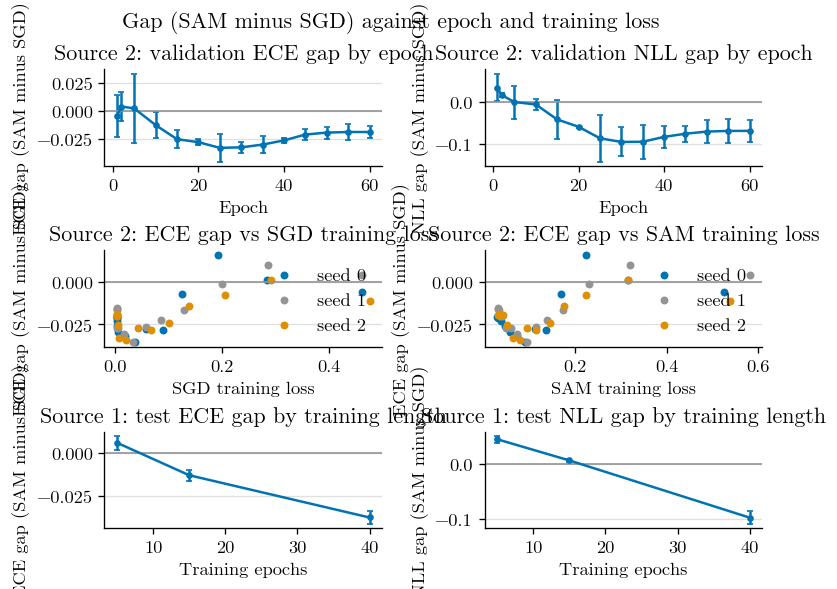

In [11]:
# Visualisation: the six panels of the original figure, drawn with matplotlib from the
# numbers main() computed (the original code called an external chart_gen.py).
print((RES / "gap_table.md").read_text())

ev = r2["epochs"]
def band(x):  # half-width of the paired-t 95% interval, as in the original make_figure
    t = paired_t(x); return float(t["tcrit"] * t["se"])
ece_mean = [float(r2["per_epoch"]["val_ece"][e].mean()) for e in ev]
nll_mean = [float(r2["per_epoch"]["val_nll"][e].mean()) for e in ev]
ece_band = [band(r2["per_epoch"]["val_ece"][e]) for e in ev]
nll_band = [band(r2["per_epoch"]["val_nll"][e]) for e in ev]
tp = (5, 15, 40)
s1_ece = [float(r1["gap_by_tp"][("ece", e)].mean()) for e in tp]
s1_nll = [float(r1["gap_by_tp"][("nll", e)].mean()) for e in tp]
s1_ece_band = [band(r1["gap_by_tp"][("ece", e)]) for e in tp]
s1_nll_band = [band(r1["gap_by_tp"][("nll", e)]) for e in tp]

fig, axes = plt.subplots(3, 2)
ax = axes.flat
ax[0].errorbar(ev, ece_mean, yerr=ece_band, color=COLOURS["method"], marker="o", ms=3, capsize=2)
ax[0].set_title("Source 2: validation ECE gap by epoch"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("ECE gap (SAM minus SGD)")
ax[1].errorbar(ev, nll_mean, yerr=nll_band, color=COLOURS["method"], marker="o", ms=3, capsize=2)
ax[1].set_title("Source 2: validation NLL gap by epoch"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("NLL gap (SAM minus SGD)")
for k, (ref_opt, title) in enumerate([("SGD", "Source 2: ECE gap vs SGD training loss"),
                                      ("SAM", "Source 2: ECE gap vs SAM training loss")]):
    for s in s2["seeds"]:
        x = [float(s2["per"][(ref_opt, s, e)]["train_loss"]) for e in ev]
        y = [float(s2["per"][("SAM", s, e)]["val_ece"] - s2["per"][("SGD", s, e)]["val_ece"]) for e in ev]
        ax[2 + k].scatter(x, y, s=14, label=f"seed {s}")
    ax[2 + k].set_title(title); ax[2 + k].set_xlabel(f"{ref_opt} training loss"); ax[2 + k].set_ylabel("ECE gap (SAM minus SGD)")
    ax[2 + k].legend()
ax[4].errorbar(tp, s1_ece, yerr=s1_ece_band, color=COLOURS["method"], marker="o", ms=3, capsize=2)
ax[4].set_title("Source 1: test ECE gap by training length"); ax[4].set_xlabel("Training epochs"); ax[4].set_ylabel("ECE gap (SAM minus SGD)")
ax[5].errorbar(tp, s1_nll, yerr=s1_nll_band, color=COLOURS["method"], marker="o", ms=3, capsize=2)
ax[5].set_title("Source 1: test NLL gap by training length"); ax[5].set_xlabel("Training epochs"); ax[5].set_ylabel("NLL gap (SAM minus SGD)")
for a in ax:
    a.axhline(0, color=COLOURS["baseline"], lw=1)
fig.suptitle("Gap (SAM minus SGD) against epoch and training loss")
plt.show()

## Interpretation

Read the printed table and figure together with the caveats below. The values quoted here are the artifact's reported numbers; the table above is what this run produced.

- **Accuracy** shows no detectable difference between SAM and SGD in either source.
- **Source 2** (3 seeds): the validation ECE and NLL gaps are near zero at epochs 1 to 5, reach their largest mean advantage near epochs 25 to 30, and then narrow. The epoch-60 endpoint is therefore not the extremum of the trajectory.
- **Source 1** (5 seeds): the test ECE gap moves from a positive value at 5 epochs to about -0.038 at 40 epochs. The 5- and 15-epoch points come from compressed schedules, so this growth is not a pure training-length effect.
- **Temperature scaling** of SGD removes most of the ECE advantage. The NLL advantage persists: at 60 epochs the NLL difference after both models are temperature-scaled is about -0.016 (parametric p about 0.035).

**Limits.** With 3 seeds the smallest exact sign-flip p-value is 0.25, and with 5 seeds it is 0.0625, so the parametric p-values are descriptive, not evidence. The gap-versus-training-loss slopes are co-variation within one trajectory, not a test of overfitting. Learning rates differ between the sources, and source 1's sits at the edge of its grid.